# Latihan SKLearn: Support Vector Regression (SVR)

Notebook ini mengikuti tahapan pada materi: mengubah CSV menjadi DataFrame, memisahkan atribut dan label, melatih SVR, lalu memplot hasilnya.

Materi lanjutan yang relevan menjelaskan bahwa SVR memprediksi nilai kontinu dan berusaha menempatkan sebanyak mungkin data di dalam margin (epsilon-insensitive tube).

## Dataset

Dataset yang disebut di bagian **Codelab** pada halaman tugas adalah **Salary data - Simple linear regression** di [Kaggle](https://www.kaggle.com/datasets/karthickveerakumar/salary-data-simple-linear-regression). File yang digunakan materi bernama `Salary_Data.csv`, dengan atribut `YearsExperience` dan label `Salary`.

Unduh dataset dari Kaggle, ekstrak ZIP jika perlu, lalu letakkan `Salary_Data.csv` di folder yang sama dengan notebook. Di Google Colab, unggah CSV melalui panel Files atau jalankan `from google.colab import files; files.upload()` lalu pilih file CSV. Notebook ini tidak membuat atau mengarang data pengganti.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.svm import SVR

## 1. Membaca dataset menjadi DataFrame

Jika file berada di lokasi lain, ubah `DATASET_PATH` menjadi path file CSV tersebut.

In [2]:
DATASET_PATH = Path("Salary_Data.csv")

if not DATASET_PATH.is_file():
    raise FileNotFoundError(
        f"File {DATASET_PATH} tidak ditemukan. Unduh Salary_Data.csv dari tautan Kaggle "
        "pada bagian Dataset di atas, ekstrak jika masih ZIP, lalu letakkan di folder notebook."
    )

data = pd.read_csv(DATASET_PATH)
required_columns = {"YearsExperience", "Salary"}
missing_columns = required_columns.difference(data.columns)
if missing_columns:
    raise ValueError(f"Kolom wajib tidak ditemukan: {sorted(missing_columns)}. Kolom CSV: {list(data.columns)}")

data.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


## 2. Memeriksa isi dan missing value

Materi menyebutkan dataset ini tidak memiliki missing value. Periksa kondisi file yang diunduh dengan `info()` dan ringkasan jumlah nilai kosong berikut.

In [3]:
data.info()
print("\nJumlah nilai kosong per kolom:")
display(data.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes

Jumlah nilai kosong per kolom:


YearsExperience    0
Salary             0
dtype: int64

## 3. Memisahkan atribut dan label

`X` berisi lama pengalaman kerja dan dibentuk sebagai array dua dimensi agar sesuai dengan input scikit-learn. `y` adalah gaji yang akan diprediksi.

In [4]:
X = data["YearsExperience"].to_numpy().reshape(-1, 1)
y = data["Salary"].to_numpy()

print("Bentuk X:", X.shape)
print("Bentuk y:", y.shape)

Bentuk X: (30, 1)
Bentuk y: (30,)


## 4. Melatih model SVR

Gunakan parameter yang dicontohkan di materi: `C=1000`, `gamma=0.05`, dan kernel `rbf`. Untuk mereproduksi latihan, data digunakan dalam skala aslinya; scaling dapat menjadi pertimbangan pada penerapan SVR di luar latihan ini.

In [5]:
svr = SVR(C=1000, gamma=0.05, kernel="rbf")
svr.fit(X, y)

print("Model SVR selesai dilatih.")

Model SVR selesai dilatih.


## 5. Plot hasil model

Titik menunjukkan data gaji sebenarnya. Garis menunjukkan prediksi model; nilai pengalaman diurutkan terlebih dahulu agar garis tidak bolak-balik.

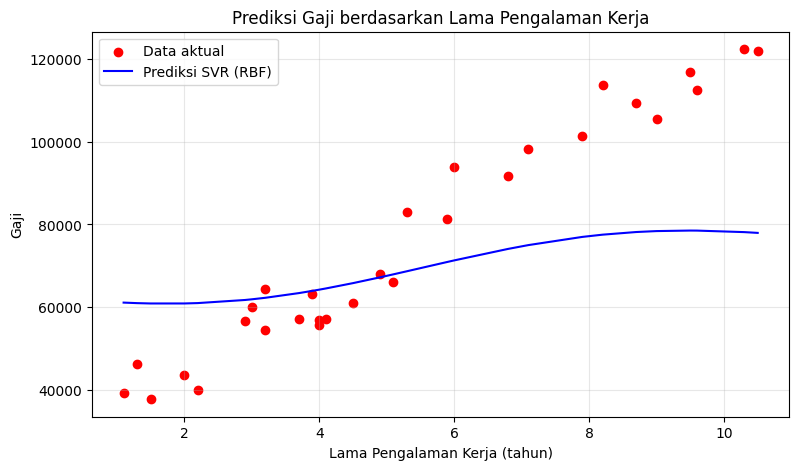

In [6]:
sort_index = np.argsort(X[:, 0])
X_sorted = X[sort_index]
y_pred_sorted = svr.predict(X_sorted)

plt.figure(figsize=(9, 5))
plt.scatter(X[:, 0], y, color="red", label="Data aktual")
plt.plot(X_sorted[:, 0], y_pred_sorted, color="blue", label="Prediksi SVR (RBF)")
plt.title("Prediksi Gaji berdasarkan Lama Pengalaman Kerja")
plt.xlabel("Lama Pengalaman Kerja (tahun)")
plt.ylabel("Gaji")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Interpretasi

Pada dataset ini, nilai `Salary` aktual berkisar 37,731–122,391, sedangkan prediksi model pada data yang sama berkisar sekitar 60,892–78,529. Kurva yang lebih datar menunjukkan bahwa parameter latihan pada skala data asli belum mengikuti rentang gaji dengan baik. Ini tetap mereproduksi pengaturan materi (`C=1000`, `gamma=0.05`, kernel `rbf`); untuk penggunaan praktis, SVR biasanya memerlukan scaling fitur dan target serta evaluasi model.

**Pertanyaan untuk laporan:** Bagaimana perubahan lama pengalaman kerja terlihat berkaitan dengan gaji? Apakah kurva SVR mengikuti seluruh pola titik, atau ada bagian yang kurang sesuai?